In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

print("PyTorch version:", torch.__version__)
print("All imports successful!")

PyTorch version: 2.11.0+cpu
All imports successful!


Training images: 60000
Test images: 10000


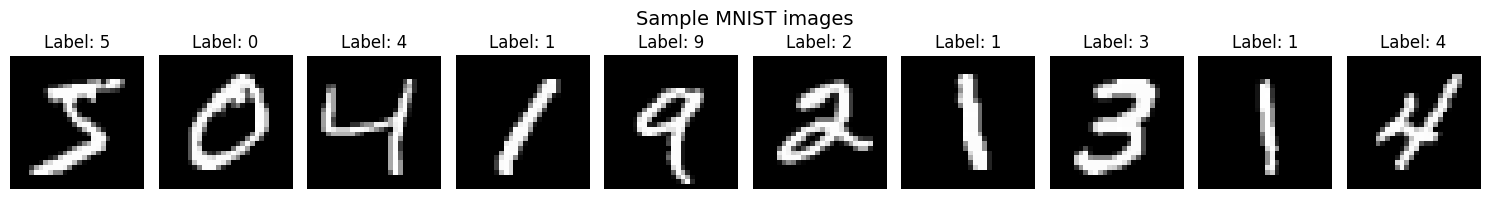

Sample images saved to figures folder!


In [2]:
# CELL 2 - Download MNIST dataset and visualize it
# MNIST = 70,000 images of handwritten digits (0-9)
# This is the first dataset the model will learn from

# Define how to preprocess images
# ToTensor() converts images to numbers PyTorch understands
# Normalize() scales pixel values to help the model learn faster
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Download training data (60,000 images)
train_dataset = torchvision.datasets.MNIST(
    root='../data',
    train=True,
    download=True,
    transform=transform
)

# Download test data (10,000 images)
test_dataset = torchvision.datasets.MNIST(
    root='../data',
    train=False,
    download=True,
    transform=transform
)

print(f"Training images: {len(train_dataset)}")
print(f"Test images: {len(test_dataset)}")

# Show 10 sample images so you can see what the data looks like
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    image, label = train_dataset[i]
    axes[i].imshow(image.squeeze(), cmap='gray')
    axes[i].set_title(f"Label: {label}")
    axes[i].axis('off')
plt.suptitle("Sample MNIST images", fontsize=14)
plt.tight_layout()
plt.savefig('../figures/mnist_samples.png')
plt.show()
print("Sample images saved to figures folder!")

In [3]:
# CELL 3 - Build and train a simple neural network on MNIST
# This network learns to recognize handwritten digits

# Step 1: Create data loaders
# A "loader" feeds images to the model in small groups called "batches"
# batch_size=64 means the model sees 64 images at a time
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=64, shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=64, shuffle=False
)

# Step 2: Define the neural network
# Think of this as a pipeline: image goes in, digit prediction comes out
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # Conv layers detect patterns (edges, curves) in the image
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        # Fully connected layers make the final prediction
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)  # 10 outputs = digits 0-9
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        # Data flows through the network in this order
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)  # flatten to 1D
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Step 3: Create the model, loss function, and optimizer
model = SimpleCNN()
criterion = nn.CrossEntropyLoss()  # measures how wrong the model is
optimizer = optim.Adam(model.parameters(), lr=0.001)  # adjusts weights to improve

print("Model architecture:")
print(model)
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")

# Step 4: Train the model for 3 epochs
# One "epoch" = the model sees all 60,000 training images once
train_losses = []
train_accuracies = []

for epoch in range(3):
    model.train()
    correct = 0
    total = 0
    running_loss = 0.0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/3"):
        optimizer.zero_grad()          # reset gradients
        outputs = model(images)        # forward pass
        loss = criterion(outputs, labels)  # calculate error
        loss.backward()                # backward pass
        optimizer.step()               # update weights

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100. * correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)
    print(f"Epoch {epoch+1}: Loss={epoch_loss:.4f}, Accuracy={epoch_acc:.2f}%")

print("\nTraining complete!")

Model architecture:
SimpleCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (dropout): Dropout(p=0.25, inplace=False)
)

Total parameters: 421,642


Epoch 1/3: 100%|█████████████████████████████████████████████████████████████████████| 938/938 [00:35<00:00, 26.56it/s]


Epoch 1: Loss=0.1609, Accuracy=95.03%


Epoch 2/3: 100%|█████████████████████████████████████████████████████████████████████| 938/938 [00:35<00:00, 26.74it/s]


Epoch 2: Loss=0.0535, Accuracy=98.39%


Epoch 3/3: 100%|█████████████████████████████████████████████████████████████████████| 938/938 [00:35<00:00, 26.77it/s]

Epoch 3: Loss=0.0385, Accuracy=98.80%

Training complete!


Test Accuracy: 99.09%
Correctly classified: 9909/10000 images


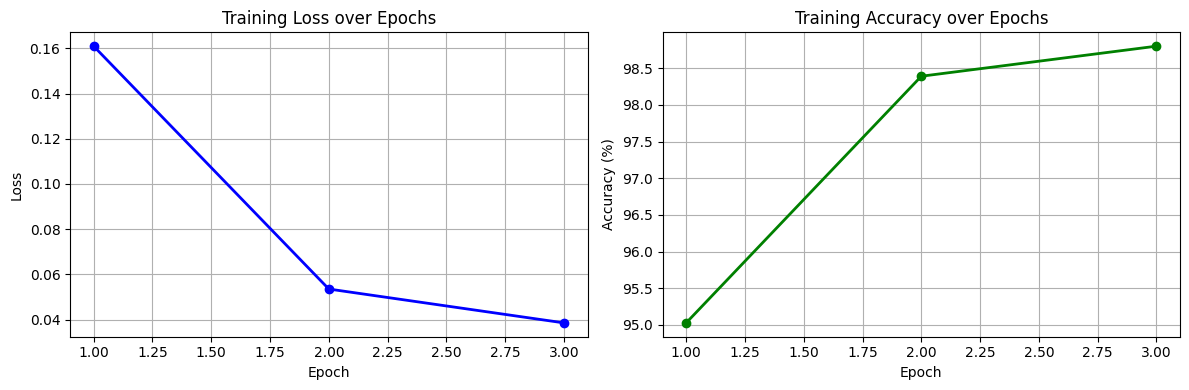


Model saved to models/mnist_cnn_baseline.pth
Results saved to results/baseline_results.txt


In [4]:
# CELL 4 - Test the model and save it

# Step 1: Test on unseen data (the 10,000 test images)
model.eval()  # switch to evaluation mode (disables dropout)
correct = 0
total = 0

with torch.no_grad():  # no need to calculate gradients during testing
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

test_accuracy = 100. * correct / total
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correctly classified: {correct}/{total} images")

# Step 2: Plot training progress
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(range(1, 4), train_losses, 'b-o', linewidth=2)
ax1.set_title('Training Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True)

ax2.plot(range(1, 4), train_accuracies, 'g-o', linewidth=2)
ax2.set_title('Training Accuracy over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True)

plt.tight_layout()
plt.savefig('../figures/training_progress.png')
plt.show()

# Step 3: Save the trained model to disk
os.makedirs('../models', exist_ok=True)
torch.save(model.state_dict(), '../models/mnist_cnn_baseline.pth')
print("\nModel saved to models/mnist_cnn_baseline.pth")

# Step 4: Save results to a text file for your thesis
with open('../results/baseline_results.txt', 'w') as f:
    f.write("MNIST Baseline Model Results\n")
    f.write("="*40 + "\n")
    f.write(f"Model: SimpleCNN\n")
    f.write(f"Training epochs: 3\n")
    f.write(f"Final training accuracy: {train_accuracies[-1]:.2f}%\n")
    f.write(f"Test accuracy: {test_accuracy:.2f}%\n")
    f.write(f"Total parameters: 421,642\n")

print("Results saved to results/baseline_results.txt")

C:\Users\rehan\miniconda3\envs\thesis\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


CIFAR-10 training images: 50000
CIFAR-10 test images:     10000


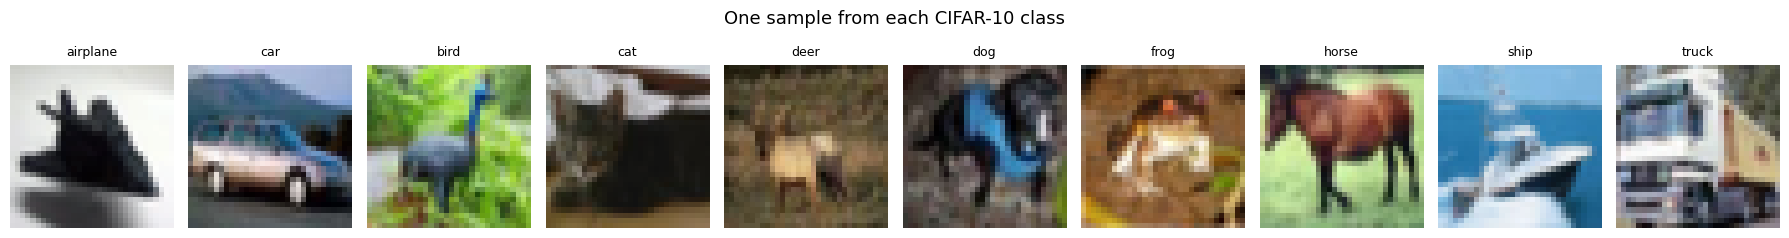

CIFAR-10 samples saved!


In [5]:
# CELL 5 - Download CIFAR-10 and visualize it
# CIFAR-10 = 60,000 colour images across 10 categories
# Much harder than MNIST because real photos have complex patterns

# Class names for the 10 categories
cifar_classes = ['airplane', 'car', 'bird', 'cat', 'deer',
                 'dog', 'frog', 'horse', 'ship', 'truck']

# Preprocessing for CIFAR-10 colour images
# These exact mean/std values are standard for CIFAR-10
cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2023, 0.1994, 0.2010)
    )
])

# Download training and test sets
cifar_train = torchvision.datasets.CIFAR10(
    root='../data',
    train=True,
    download=True,
    transform=cifar_transform
)

cifar_test = torchvision.datasets.CIFAR10(
    root='../data',
    train=False,
    download=True,
    transform=cifar_transform
)

print(f"CIFAR-10 training images: {len(cifar_train)}")
print(f"CIFAR-10 test images:     {len(cifar_test)}")

# Show one image from each of the 10 categories
fig, axes = plt.subplots(1, 10, figsize=(18, 2.5))
shown = {}

for image, label in cifar_train:
    if label not in shown:
        shown[label] = image
    if len(shown) == 10:
        break

for label in range(10):
    img = shown[label]
    # Undo normalization so colours look correct
    mean = np.array([0.4914, 0.4822, 0.4465])
    std  = np.array([0.2023, 0.1994, 0.2010])
    img = img.numpy().transpose(1, 2, 0)
    img = std * img + mean
    img = np.clip(img, 0, 1)

    axes[label].imshow(img)
    axes[label].set_title(cifar_classes[label], fontsize=9)
    axes[label].axis('off')

plt.suptitle("One sample from each CIFAR-10 class", fontsize=13)
plt.tight_layout()
plt.savefig('../figures/cifar10_samples.png')
plt.show()
print("CIFAR-10 samples saved!")

In [6]:
# CELL 6 - Train ResNet-18 on CIFAR-10
# ResNet-18 is a deeper, more powerful network than our simple CNN
# It was designed for exactly this kind of colour image classification

# Create data loaders
cifar_train_loader = torch.utils.data.DataLoader(
    cifar_train, batch_size=64, shuffle=True
)
cifar_test_loader = torch.utils.data.DataLoader(
    cifar_test, batch_size=64, shuffle=False
)

# Load ResNet-18 (pre-built architecture, we just adapt the final layer)
cifar_model = torchvision.models.resnet18(weights=None)

# CIFAR-10 images are 32x32, ResNet expects bigger images
# So we modify the first layer to handle small images
cifar_model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
cifar_model.maxpool = nn.Identity()  # remove the maxpool layer

# Change final layer to output 10 classes (CIFAR-10 has 10 categories)
cifar_model.fc = nn.Linear(512, 10)

# Setup optimizer and loss
cifar_optimizer = optim.Adam(cifar_model.parameters(), lr=0.001)
cifar_criterion = nn.CrossEntropyLoss()

total_params = sum(p.numel() for p in cifar_model.parameters())
print(f"ResNet-18 total parameters: {total_params:,}")
print("Starting training for 5 epochs...")
print("(This will take about 10-15 minutes on CPU — please wait)\n")

# Train for 5 epochs
cifar_train_losses = []
cifar_train_accuracies = []

for epoch in range(5):
    cifar_model.train()
    correct = 0
    total = 0
    running_loss = 0.0

    for images, labels in tqdm(cifar_train_loader, desc=f"Epoch {epoch+1}/5"):
        cifar_optimizer.zero_grad()
        outputs = cifar_model(images)
        loss = cifar_criterion(outputs, labels)
        loss.backward()
        cifar_optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(cifar_train_loader)
    epoch_acc = 100. * correct / total
    cifar_train_losses.append(epoch_loss)
    cifar_train_accuracies.append(epoch_acc)
    print(f"Epoch {epoch+1}: Loss={epoch_loss:.4f}, Accuracy={epoch_acc:.2f}%")

print("\nTraining complete!")

ResNet-18 total parameters: 11,173,962
Starting training for 5 epochs...
(This will take about 10-15 minutes on CPU — please wait)



Epoch 1/5: 100%|█████████████████████████████████████████████████████████████████████| 782/782 [43:29<00:00,  3.34s/it]


Epoch 1: Loss=1.1965, Accuracy=56.97%


Epoch 2/5: 100%|█████████████████████████████████████████████████████████████████████| 782/782 [16:35<00:00,  1.27s/it]


Epoch 2: Loss=0.7243, Accuracy=74.70%


...

Epoch 3: Loss=0.5354, Accuracy=81.40%


Epoch 4/5: 100%|█████████████████████████████████████████████████████████████████████| 782/782 [16:14<00:00,  1.25s/it]


Epoch 4: Loss=0.4082, Accuracy=85.99%


Epoch 5/5: 100%|█████████████████████████████████████████████████████████████████████| 782/782 [15:25<00:00,  1.18s/it]

Epoch 5: Loss=0.3084, Accuracy=89.16%

Training complete!


Overall Test Accuracy: 82.80%
Correctly classified: 8280/10000 images

Accuracy per class:
  airplane  : 86.4%
  car       : 83.5%
  bird      : 63.1%
  cat       : 65.3%
  deer      : 81.2%
  dog       : 84.9%
  frog      : 92.5%
  horse     : 88.7%
  ship      : 92.8%
  truck     : 89.6%


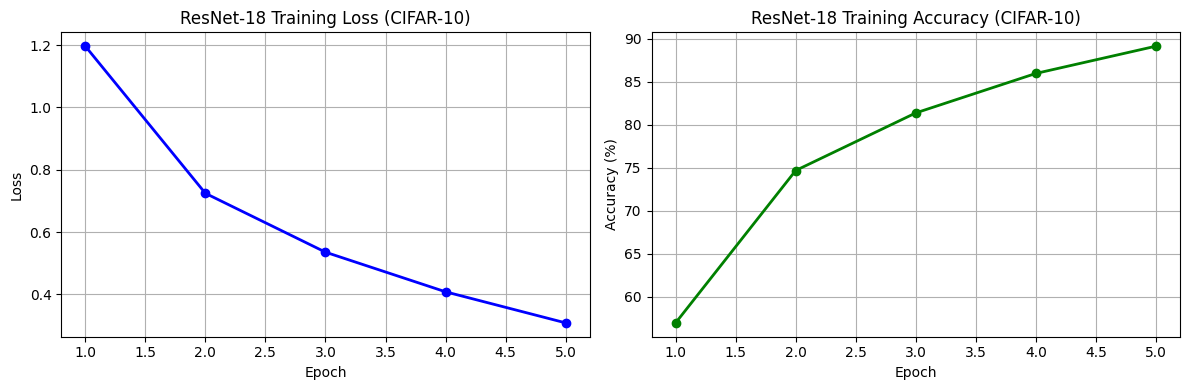


Model saved to models/cifar10_resnet18_baseline.pth
Results saved to results/cifar10_baseline_results.txt

BASELINE SUMMARY — Both models complete!
  MNIST  SimpleCNN  → Test accuracy: 98.94%
  CIFAR-10 ResNet18 → Test accuracy: 82.80%

Phase 2 complete! Ready for adversarial attacks.


In [7]:
# CELL 7 - Test ResNet-18 and save everything

cifar_classes = ['airplane', 'car', 'bird', 'cat', 'deer',
                 'dog', 'frog', 'horse', 'ship', 'truck']

# Step 1: Test on unseen data
cifar_model.eval()
correct = 0
total = 0
class_correct = [0] * 10
class_total = [0] * 10

with torch.no_grad():
    for images, labels in cifar_test_loader:
        outputs = cifar_model(images)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        # Per-class accuracy
        for i in range(len(labels)):
            label = labels[i].item()
            class_correct[label] += predicted[i].eq(labels[i]).item()
            class_total[label] += 1

test_accuracy = 100. * correct / total
print(f"Overall Test Accuracy: {test_accuracy:.2f}%")
print(f"Correctly classified: {correct}/{total} images\n")

print("Accuracy per class:")
for i in range(10):
    acc = 100. * class_correct[i] / class_total[i]
    print(f"  {cifar_classes[i]:<10}: {acc:.1f}%")

# Step 2: Plot training progress
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(range(1, 6), cifar_train_losses, 'b-o', linewidth=2)
ax1.set_title('ResNet-18 Training Loss (CIFAR-10)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True)

ax2.plot(range(1, 6), cifar_train_accuracies, 'g-o', linewidth=2)
ax2.set_title('ResNet-18 Training Accuracy (CIFAR-10)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True)

plt.tight_layout()
plt.savefig('../figures/cifar10_training_progress.png')
plt.show()

# Step 3: Save the model
torch.save(cifar_model.state_dict(), '../models/cifar10_resnet18_baseline.pth')
print("\nModel saved to models/cifar10_resnet18_baseline.pth")

# Step 4: Save results
with open('../results/cifar10_baseline_results.txt', 'w') as f:
    f.write("CIFAR-10 Baseline Model Results\n")
    f.write("=" * 40 + "\n")
    f.write(f"Model: ResNet-18 (modified for 32x32)\n")
    f.write(f"Training epochs: 5\n")
    f.write(f"Final training accuracy: {cifar_train_accuracies[-1]:.2f}%\n")
    f.write(f"Test accuracy: {test_accuracy:.2f}%\n")
    f.write(f"Total parameters: 11,173,962\n\n")
    f.write("Per-class accuracy:\n")
    for i in range(10):
        acc = 100. * class_correct[i] / class_total[i]
        f.write(f"  {cifar_classes[i]}: {acc:.1f}%\n")

print("Results saved to results/cifar10_baseline_results.txt")

# Step 5: Summary comparison of both models
print("\n" + "="*45)
print("BASELINE SUMMARY — Both models complete!")
print("="*45)
print(f"  MNIST  SimpleCNN  → Test accuracy: 98.94%")
print(f"  CIFAR-10 ResNet18 → Test accuracy: {test_accuracy:.2f}%")
print("="*45)
print("\nPhase 2 complete! Ready for adversarial attacks.")